In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Sampling physical quantities with gaussian distribution: direct sampling and Metropolis sampling

In [2]:
def psi(x, sigma):

    return np.exp(-x**2 / (4 * sigma**2))

def d2psi(x, sigma):

    return (x**2 / (4 * sigma**4) - 1 / (2 * sigma**2)) * psi(x, sigma)

def monte_carlo_expectation_values(sigma=1.0, num_samples=1000000, L=5.0):

    x = np.random.uniform(-L, L, num_samples)
    domain_volume = 2.0 * L  # b - a
    
    p_vals = psi(x, sigma)
    psi_sq = p_vals**2
    
    norm_integrand = psi_sq
    x_integrand = x * psi_sq
    
    kin_integrand = -0.5 * p_vals * d2psi(x, sigma)
    
    pot_integrand = 0.5 * (x**2) * psi_sq
    
    norm_integral = (domain_volume / num_samples) * np.sum(norm_integrand)
    x_integral = (domain_volume / num_samples) * np.sum(x_integrand)
    kin_integral = (domain_volume / num_samples) * np.sum(kin_integrand)
    pot_integral = (domain_volume / num_samples) * np.sum(pot_integrand)
    
    mean_x = x_integral / norm_integral
    mean_kinetic_energy = kin_integral / norm_integral
    mean_potential_energy = pot_integral / norm_integral
    
    return mean_x, mean_kinetic_energy, mean_potential_energy

In [3]:
sigma = 1.0

ex_kenergy = 1/(8*sigma**2)
ex_penergy = 0.5*sigma**2

mean_x, e_kin, e_pot = monte_carlo_expectation_values(sigma=sigma, num_samples=2000000, L=6.0*sigma)

print(f"Parameters: sigma = {sigma}")
print(f"First Moment ⟨x⟩:          {mean_x:.6f} expected: 0")
print(f"Kinetic Energy ⟨E_k⟩:      {e_kin:.6f} expected: {ex_kenergy:.6f}")
print(f"Potential Energy ⟨E_p⟩:    {e_pot:.6f} expected: {ex_penergy:.6f}")

Parameters: sigma = 1.0
First Moment ⟨x⟩:          -0.000015 expected: 0
Kinetic Energy ⟨E_k⟩:      0.125086 expected: 0.125000
Potential Energy ⟨E_p⟩:    0.499654 expected: 0.500000


In [4]:
N = np.arange(100, 10e5, 1000, dtype='int32')

kenergy = []
penergy = []
momenta = []

for i in N:

    mean_x, e_kin, e_pot = monte_carlo_expectation_values(sigma=sigma, num_samples=i, L=6.0*sigma)
    
    kenergy.append(e_kin)
    penergy.append(e_pot)
    momenta.append(mean_x)
 

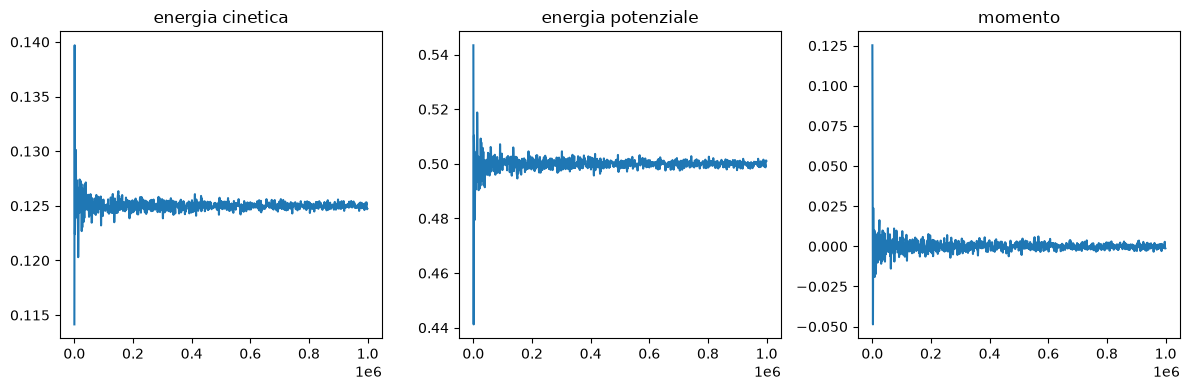

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(12,4))

ax[0].plot(N, kenergy)
ax[0].set_title('energia cinetica')
ax[1].plot(N, penergy)
ax[1].set_title('energia potenziale')
ax[2].plot(N, momenta)
ax[2].set_title('momento')

plt.tight_layout()
plt.show()

In [6]:
err_kinenergy = []
err_potenergy = []

for i in kenergy:

    err_kinenergy.append(i - ex_kenergy)

for j in penergy:

    err_potenergy.append(j - ex_penergy)

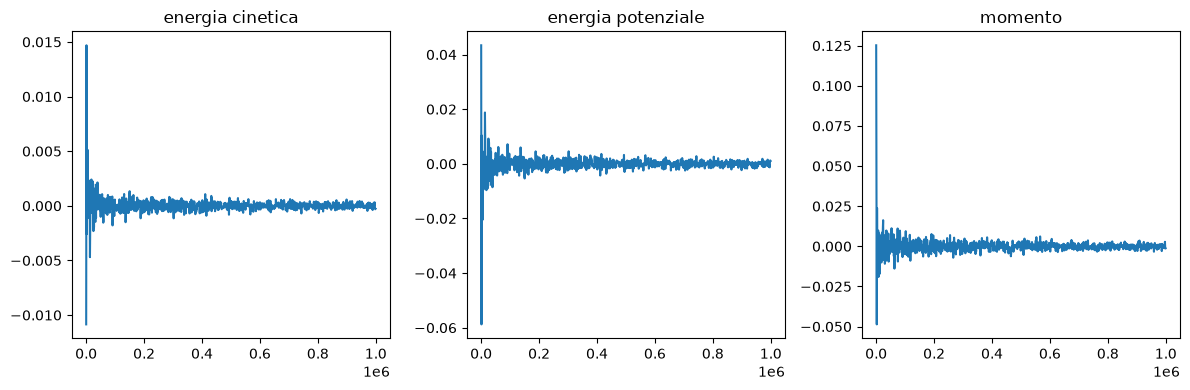

In [7]:
fig, ax = plt.subplots(1, 3, figsize=(12,4))

ax[0].plot(N, err_kinenergy)
ax[0].set_title('energia cinetica')
ax[1].plot(N, err_potenergy)
ax[1].set_title('energia potenziale')
ax[2].plot(N, momenta)
ax[2].set_title('momento')

plt.tight_layout()
plt.show()

In [8]:
def metropolis_expectation_values(sigma=1.0, num_samples=10000, delta=1.5, x0=0.0):
    
    acc = 0.0
    x1 = 0.0
    x2 = 0.0
    x3 = 0.0
    x4 = 0.0
    ekin_sum = 0.0
    epot_sum = 0.0

    exp_current = - (x0**2) / (2.0 * sigma**2)

    for i in range(num_samples):

        local_ekin = -0.5 * ((x0 / (2.0 * sigma**2))**2 - 1.0 / (2.0 * sigma**2))
        local_epot = 0.5 * (x0**2)
        
        ekin_sum += local_ekin
        epot_sum += local_epot
        
        x1 += x0
        x2 += x0**2
        x3 += x0**3
        x4 += x0**4

        rand_step = np.random.rand() - 0.5 
        xp = x0 + delta * rand_step
        
        exp_proposal = - (xp**2) / (2.0 * sigma**2)
        w = np.exp(exp_proposal - exp_current)
        
        if np.random.rand() < w:
            x0 = xp
            exp_current = exp_proposal
            acc += 1.0

    acceptance_rate = acc / num_samples
    mean_x1 = x1 / num_samples
    mean_x2 = x2 / num_samples
    mean_x3 = x3 / num_samples
    mean_x4 = x4 / num_samples
    mean_ekin = ekin_sum / num_samples
    mean_epot = epot_sum / num_samples
    mean_etot = mean_ekin + mean_epot

    return acceptance_rate, mean_x1, mean_x2, mean_x3, mean_x4, mean_ekin, mean_epot, mean_etot

In [9]:
acc_rate, x1, x2, x3, x4, ekin, epot, etot = metropolis_expectation_values()
print(f"Acceptance Rate: {acc_rate * 100:.2f}%")
print(f"⟨x⟩:   {x1:.6f}")
print(f"⟨x²⟩:  {x2:.6f}")
print(f"⟨E_k⟩: {ekin:.6f}")
print(f"⟨E_p⟩: {epot:.6f}")
print(f"⟨E⟩:   {etot:.6f}")

Acceptance Rate: 86.03%
⟨x⟩:   -0.008134
⟨x²⟩:  0.925387
⟨E_k⟩: 0.134327
⟨E_p⟩: 0.462693
⟨E⟩:   0.597020


In [10]:
N = np.arange(100, 10e5, 10000, dtype='int32')

kenergy = []
penergy = []
momenta = []

for i in N:

    acc_rate, x1, x2, x3, x4, ekin, epot, etot = metropolis_expectation_values(num_samples=i)
    
    kenergy.append(ekin)
    penergy.append(epot)
    momenta.append(x1)


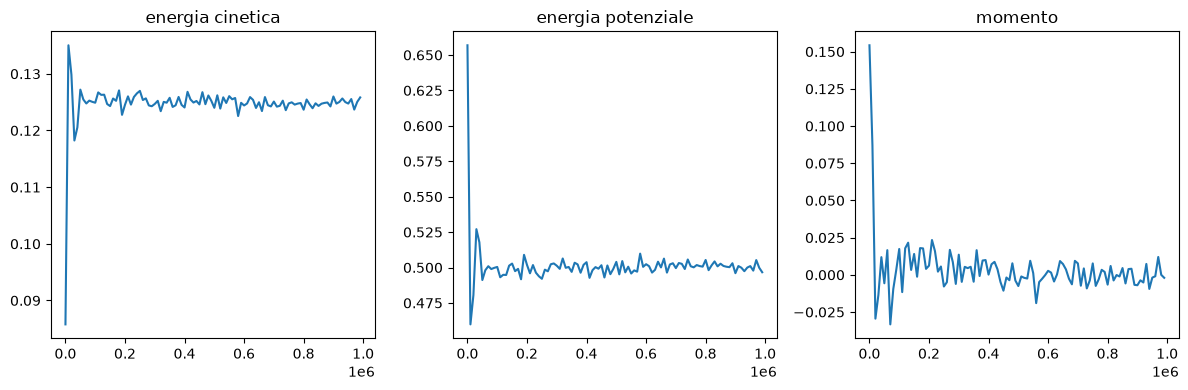

In [11]:
fig, ax = plt.subplots(1, 3, figsize=(12,4))

ax[0].plot(N, kenergy)
ax[0].set_title('energia cinetica')
ax[1].plot(N, penergy)
ax[1].set_title('energia potenziale')
ax[2].plot(N, momenta)
ax[2].set_title('momento')

plt.tight_layout()
plt.show()

In [12]:
err_kinenergy = []
err_potenergy = []

for i in kenergy:

    err_kinenergy.append(i - ex_kenergy)

for j in penergy:

    err_potenergy.append(j - ex_penergy)

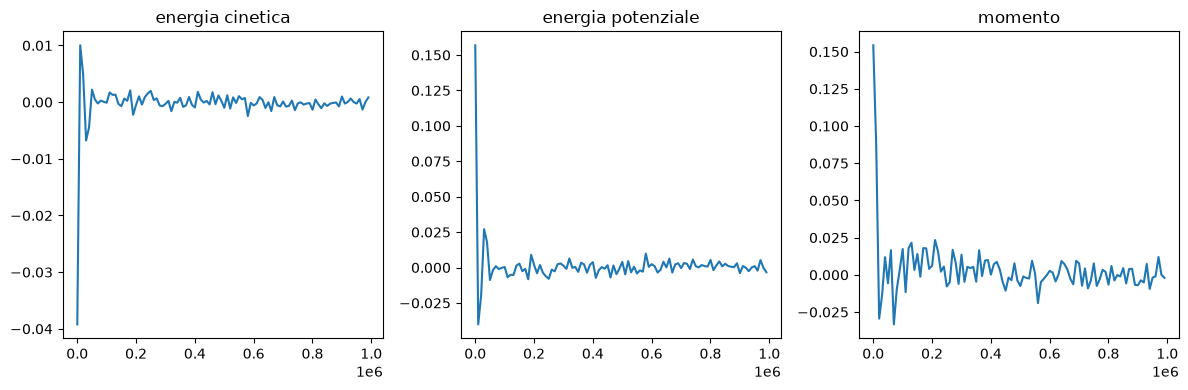

In [13]:
fig, ax = plt.subplots(1, 3, figsize=(12,4))

ax[0].plot(N, err_kinenergy)
ax[0].set_title('energia cinetica')
ax[1].plot(N, err_potenergy)
ax[1].set_title('energia potenziale')
ax[2].plot(N, momenta)
ax[2].set_title('momento')

plt.tight_layout()
plt.show()

# Ising Model on a square lattice - part I

In [4]:
L = 30             
T = 2        
nequil = 2000      
nmcs = 5000        
np.random.seed(42)  

N = L * L

w = {dE: np.exp(-dE / T) for dE in [-8, -4, 0, 4, 8]}

total_accept = 0

In [5]:
lattice = np.random.choice([-1,1], size=(L,L))

In [6]:
def calculate_energy(lattice, J=1.0):

    neighbors_sum = (
        np.roll(lattice, 1, axis=0) +  
        np.roll(lattice, -1, axis=0) + 
        np.roll(lattice, 1, axis=1) + 
        np.roll(lattice, -1, axis=1)   
    )
    
    total_energy = -0.5 * J * np.sum(lattice * neighbors_sum)
    return total_energy

In [7]:
def metropolis_step(lattice, E, M, w, L):
    accept = 0
    xs = np.random.randint(0, L, size=N)
    ys = np.random.randint(0, L, size=N)
    rands = np.random.random(size=N)
    
    for i in range(N):
        x, y = xs[i], ys[i]
        s = lattice[x, y]
        
        neighbors = (
            lattice[(x + 1) % L, y] +
            lattice[(x - 1) % L, y] +
            lattice[x, (y + 1) % L] +
            lattice[x, (y - 1) % L]
        )
        
        dE = 2 * s * neighbors
        
        if rands[i] <= w[dE]:
            lattice[x, y] = -s
            accept += 1
            E += dE
            M += 2 * lattice[x, y]
            
    return E, M, accept

In [8]:
E = calculate_energy(lattice)
M = np.sum(lattice)

In [9]:
for _ in range(nequil):
    E, M, acc = metropolis_step(lattice, E, M, w, L)
    total_accept += acc

In [10]:
cum = np.zeros(5, dtype=np.float64)

In [11]:
for _ in range(nmcs):
    E, M, acc = metropolis_step(lattice, E, M, w, L)
    total_accept += acc
    
    cum[0] += E
    cum[1] += E * E
    cum[2] += M
    cum[3] += M * M
    cum[4] += abs(M)

In [12]:
acceptance_prob = total_accept / (N * (nmcs + nequil))
eave     = cum[0] / (N * nmcs)
e2ave    = cum[1] / (N**2 * nmcs)
mave     = cum[2] / (N * nmcs)
m2ave    = cum[3] / (N**2 * nmcs)
abs_mave = cum[4] / (N * nmcs)

In [13]:
print(f"temperature                         = {T}")
print(f"acceptance probability              = {acceptance_prob:.6f}")
print(f"mean energy per spin                = {eave:.6f}")
print(f"mean squared energy per spin        = {e2ave:.6f}")
print(f"mean magnetization per spin         = {mave:.6f}")
print(f"mean squared magnetization per spin = {m2ave:.6f}")
print(f"mean |magnetization| per spin       = {abs_mave:.6f}")

temperature                         = 2
acceptance probability              = 0.081577
mean energy per spin                = -1.744876
mean squared energy per spin        = 3.047755
mean magnetization per spin         = -0.911811
mean squared magnetization per spin = 0.832143
mean |magnetization| per spin       = 0.911811


In [14]:
up_coords = np.argwhere(lattice == 1) + 1
down_coords = np.argwhere(lattice == -1) + 1

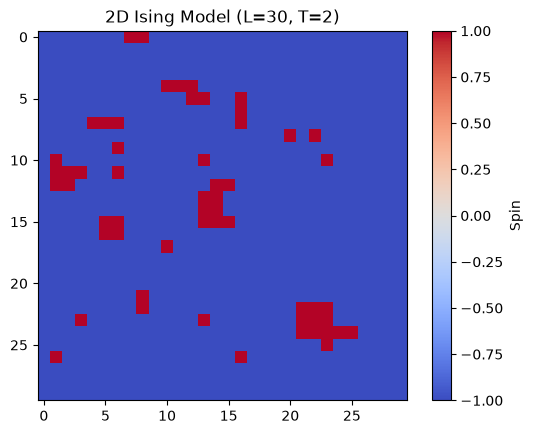

In [15]:
plt.imshow(lattice, cmap="coolwarm", interpolation="nearest")
plt.title(f"2D Ising Model (L={L}, T={T})")
plt.colorbar(label="Spin")
plt.show()

In [16]:
L = 30             
T = 4        
nequil = 2000      
nmcs = 5000        
np.random.seed(42)  

N = L * L

w = {dE: np.exp(-dE / T) for dE in [-8, -4, 0, 4, 8]}

total_accept = 0

In [17]:
lattice = np.random.choice([-1,1], size=(L,L))

In [18]:
E = calculate_energy(lattice)
M = np.sum(lattice)

In [19]:
for _ in range(nequil):
    E, M, acc = metropolis_step(lattice, E, M, w, L)
    total_accept += acc

In [20]:
cum = np.zeros(5, dtype=np.float64)

In [21]:
for _ in range(nmcs):
    E, M, acc = metropolis_step(lattice, E, M, w, L)
    total_accept += acc
    
    cum[0] += E
    cum[1] += E * E
    cum[2] += M
    cum[3] += M * M
    cum[4] += abs(M)

In [22]:
acceptance_prob = total_accept / (N * (nmcs + nequil))
eave     = cum[0] / (N * nmcs)
e2ave    = cum[1] / (N**2 * nmcs)
mave     = cum[2] / (N * nmcs)
m2ave    = cum[3] / (N**2 * nmcs)
abs_mave = cum[4] / (N * nmcs)

In [23]:
print(f"temperature                         = {T}")
print(f"acceptance probability              = {acceptance_prob:.6f}")
print(f"mean energy per spin                = {eave:.6f}")
print(f"mean squared energy per spin        = {e2ave:.6f}")
print(f"mean magnetization per spin         = {mave:.6f}")
print(f"mean squared magnetization per spin = {m2ave:.6f}")
print(f"mean |magnetization| per spin       = {abs_mave:.6f}")

temperature                         = 4
acceptance probability              = 0.609853
mean energy per spin                = -0.555620
mean squared energy per spin        = 0.311751
mean magnetization per spin         = 0.003760
mean squared magnetization per spin = 0.004967
mean |magnetization| per spin       = 0.056137


In [24]:
up_coords = np.argwhere(lattice == 1) + 1
down_coords = np.argwhere(lattice == -1) + 1

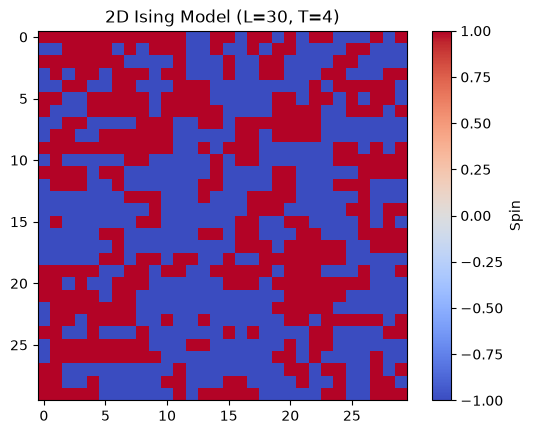

In [25]:
plt.imshow(lattice, cmap="coolwarm", interpolation="nearest")
plt.title(f"2D Ising Model (L={L}, T={T})")
plt.colorbar(label="Spin")
plt.show()